# INSTITUTO / UNIVERSIDAD [Nombre de tu institución]

## Asignatura: Investigación de Operaciones
## Programa Educativo: Ingeniería en Computación
## Actividad Integradora — Implementación de Modelos de IO con Python

### Integrantes del equipo:
- Akis Aram Seba Toto
- Cristian Saul Soto Vique
- Luis Alberto Rodiguez Rodriguez
### Fecha: [19/11/2026]
### Herramientas: Python 3, Jupyter Notebook, NetworkX, Matplotlib, NumPy, Pandas, SciPy

## Práctica 1: Árbol de Expansión Mínima (MST)

### Planteamiento del problema (contexto TI)
Una empresa de TI necesita conectar **8 sucursales** (servidores distribuidos) con fibra óptica.
Los costos de instalación entre pares de sucursales se conocen.
Se requiere determinar la red de conexión de **menor costo total** que conecte todas las sucursales
sin ciclos (esto es, un Árbol de Expansión Mínima).

### Formulación matemática
Sea G = (V, E) con pesos w(e) ≥ 0.
Minimizar:  ∑_{e ∈ T} w(e)
Sujeto a:   T ⊆ E es un árbol que conecta todos los vértices de V.

Algoritmo elegido: **Kruskal** (ordena aristas por peso y las añade si no forman ciclo).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from scipy.optimize import linprog
import heapq

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

In [3]:
nodos_mst = ['S1','S2','S3','S4','S5','S6','S7','S8']

aristas_mst = [
    ('S1','S2', 4), ('S1','S3', 8), ('S2','S3', 11),
    ('S2','S4', 8), ('S3','S4', 7), ('S3','S5', 2),
    ('S4','S5', 6), ('S4','S6', 9), ('S5','S6', 4),
    ('S6','S7', 10), ('S6','S8', 3), ('S7','S8', 5),
    ('S5','S8', 12), ('S1','S8', 15)
]

G_mst = nx.Graph()
G_mst.add_weighted_edges_from(aristas_mst)

print(f"Nodos: {G_mst.number_of_nodes()}")
print(f"Aristas: {G_mst.number_of_edges()}")

Nodos: 8
Aristas: 14


## Práctica 2: Ruta Crítica (PERT/CPM)

### Planteamiento (contexto TI)
Proyecto de desarrollo de software con 10 actividades. Se conocen duraciones y precedencias.
Se requiere calcular: ES, EF, LS, LF, holguras, ruta crítica y duración total.

### Formulación
- ES(i) = max{ EF(j) : j precede a i }
- EF(i) = ES(i) + duración(i)
- LF(i) = min{ LS(k) : k sucesor de i }
- LS(i) = LF(i) - duración(i)
- Holgura(i) = LS(i) - ES(i)  (o LF - EF)
- Ruta crítica: actividades con holgura = 0.

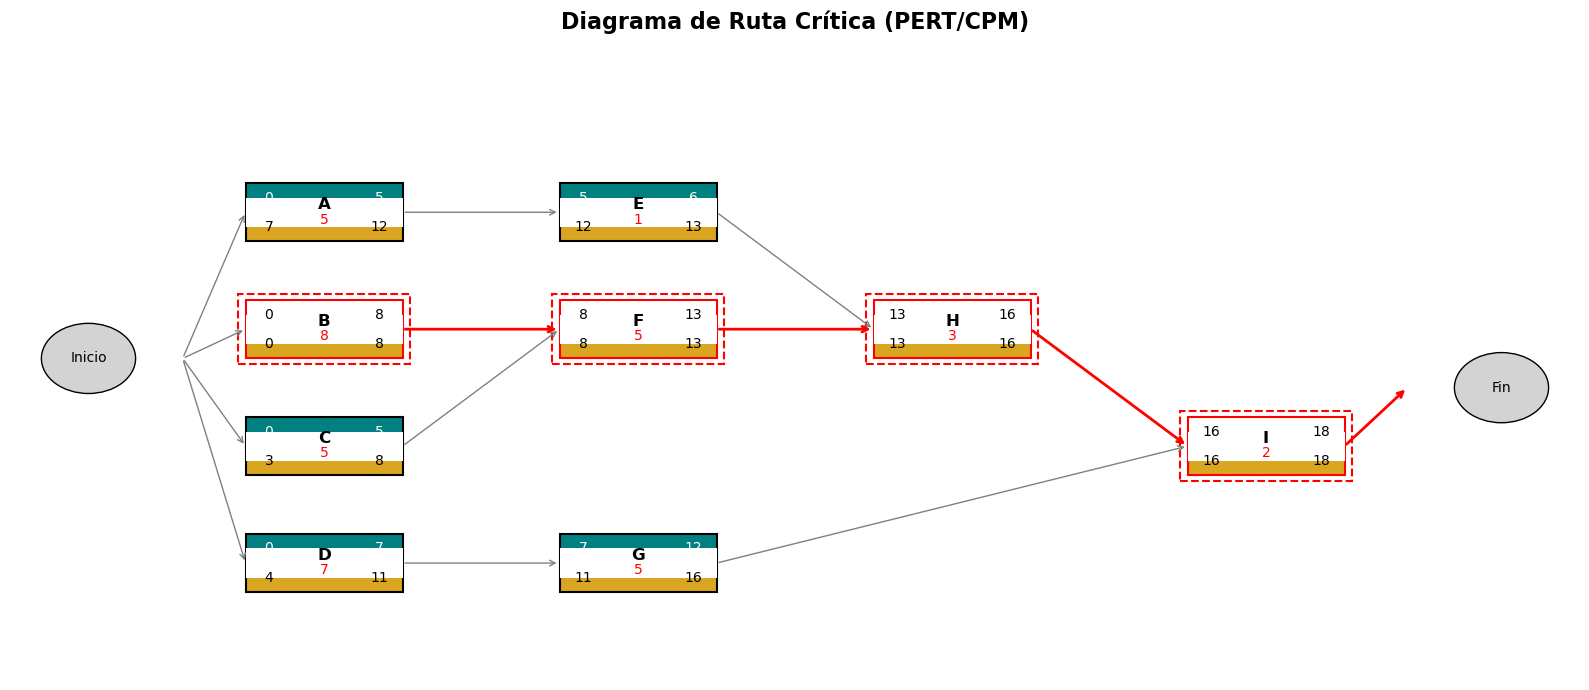

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

datos_actividades = {
    'A': {'x': 2,  'y': 3, 'ES': 0,  'EF': 5, 'LS': 7,  'LF': 12, 'dur': 5, 'critica': False},
    'B': {'x': 2,  'y': 2, 'ES': 0,  'EF': 8, 'LS': 0,  'LF': 8,  'dur': 8, 'critica': True},
    'C': {'x': 2,  'y': 1, 'ES': 0,  'EF': 5, 'LS': 3,  'LF': 8,  'dur': 5, 'critica': False},
    'D': {'x': 2,  'y': 0, 'ES': 0,  'EF': 7, 'LS': 4,  'LF': 11, 'dur': 7, 'critica': False},
    'E': {'x': 4,  'y': 3, 'ES': 5,  'EF': 6, 'LS': 12, 'LF': 13, 'dur': 1, 'critica': False},
    'F': {'x': 4,  'y': 2, 'ES': 8,  'EF': 13,'LS': 8,  'LF': 13, 'dur': 5, 'critica': True},
    'G': {'x': 4,  'y': 0, 'ES': 7,  'EF': 12,'LS': 11, 'LF': 16, 'dur': 5, 'critica': False},
    'H': {'x': 6,  'y': 2, 'ES': 13, 'EF': 16,'LS': 13, 'LF': 16, 'dur': 3, 'critica': True},
    'I': {'x': 8,  'y': 1, 'ES': 16, 'EF': 18,'LS': 16, 'LF': 18, 'dur': 2, 'critica': True},
}

flechas = [
    ('Inicio', 'A'), ('Inicio', 'B'), ('Inicio', 'C'), ('Inicio', 'D'),
    ('A', 'E'), ('B', 'F'), ('C', 'F'), ('D', 'G'),
    ('E', 'H'), ('F', 'H'), ('G', 'I'), ('H', 'I'),
    ('I', 'Fin')
]

fig, ax = plt.subplots(figsize=(16, 7))
ax.set_xlim(0, 10)
ax.set_ylim(-1, 4.5)
ax.axis('off')

def dibujar_caja(ax, x, y, nombre, es, ef, ls, lf, dur, critica):
    w, h = 1.0, 0.5
    color_relleno = 'teal' if not critica else 'white'
    color_linea = 'black' if not critica else 'red'
    color_texto_top = 'white' if not critica else 'black'
    
    rect_top = patches.Rectangle((x - w/2, y), w, h/2, linewidth=1.5, 
                                 edgecolor=color_linea, facecolor=color_relleno)
    ax.add_patch(rect_top)
    ax.text(x - 0.35, y + h/4, str(es), ha='center', va='center', color=color_texto_top)
    ax.text(x + 0.35, y + h/4, str(ef), ha='center', va='center', color=color_texto_top)
    
    rect_bot = patches.Rectangle((x - w/2, y - h/2), w, h/2, linewidth=1.5, 
                                 edgecolor=color_linea, facecolor='goldenrod')
    ax.add_patch(rect_bot)
    ax.text(x - 0.35, y - h/4, str(ls), ha='center', va='center')
    ax.text(x + 0.35, y - h/4, str(lf), ha='center', va='center')
    
    rect_mid = patches.Rectangle((x - w/2, y - h/4), w, h/2, linewidth=1.5, 
                                 edgecolor='none', facecolor='white')
    ax.add_patch(rect_mid)
    ax.text(x, y + h/8, nombre, ha='center', va='center', fontweight='bold', fontsize=12)
    ax.text(x, y - h/8, str(dur), ha='center', va='center', color='red')
    
    if critica:
        rect_borde = patches.Rectangle((x - w/2 - 0.05, y - h/2 - 0.05), w + 0.1, h + 0.1, 
                                       linewidth=1.5, edgecolor='red', facecolor='none', linestyle='--')
        ax.add_patch(rect_borde)

def dibujar_nodo(ax, x, y, texto):
    circulo = patches.Circle((x, y), radius=0.3, edgecolor='black', facecolor='lightgray')
    ax.add_patch(circulo)
    ax.text(x, y, texto, ha='center', va='center', fontsize=10)

dibujar_nodo(ax, 0.5, 1.75, 'Inicio')
dibujar_nodo(ax, 9.5, 1.5, 'Fin')

posiciones = {'Inicio': (0.8, 1.75), 'Fin': (9.2, 1.5)}

for nombre, d in datos_actividades.items():
    dibujar_caja(ax, d['x'], d['y'], nombre, d['ES'], d['EF'], d['LS'], d['LF'], d['dur'], d['critica'])
    posiciones[nombre] = (d['x'], d['y'])

for origen, destino in flechas:
    x1, y1 = posiciones[origen]
    x2, y2 = posiciones[destino]
    
    if origen == 'Inicio': x1 += 0.3
    else: x1 += 0.5
    if destino == 'Fin': x2 -= 0.3
    else: x2 -= 0.5
    
    es_critica = False
    if origen in datos_actividades and datos_actividades[origen]['critica'] and destino in datos_actividades and datos_actividades[destino]['critica']:
        es_critica = True
    elif destino == 'Fin' and datos_actividades[origen]['critica']:
        es_critica = True

    color_flecha = 'red' if es_critica else 'gray'
    grosor = 2 if es_critica else 1
    
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", color=color_flecha, lw=grosor))

plt.title("Diagrama de Ruta Crítica (PERT/CPM)", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretación
- **Duración total del proyecto**: ver salida de `duracion_total`.
- **Ruta crítica**: actividades con holgura 0 → no pueden retrasarse.
- Cualquier retraso en la ruta crítica retrasa el proyecto completo.
- **Aplicación TI**: planificación de sprints, despliegues, migraciones.

## Práctica 3: Ruta más corta con Dijkstra

### Planteamiento (contexto TI)
Red de 8 routers/ciudades. Se requiere la ruta más corta entre el nodo A y el nodo H
(menor latencia acumulada).

### Formulación
- Grafo G = (V, E) con pesos w ≥ 0.
- Encontrar el camino P de A a H que minimice ∑ w(e) para e ∈ P.
- Algoritmo de Dijkstra con cola de prioridad: complejidad O((V+E) log V).

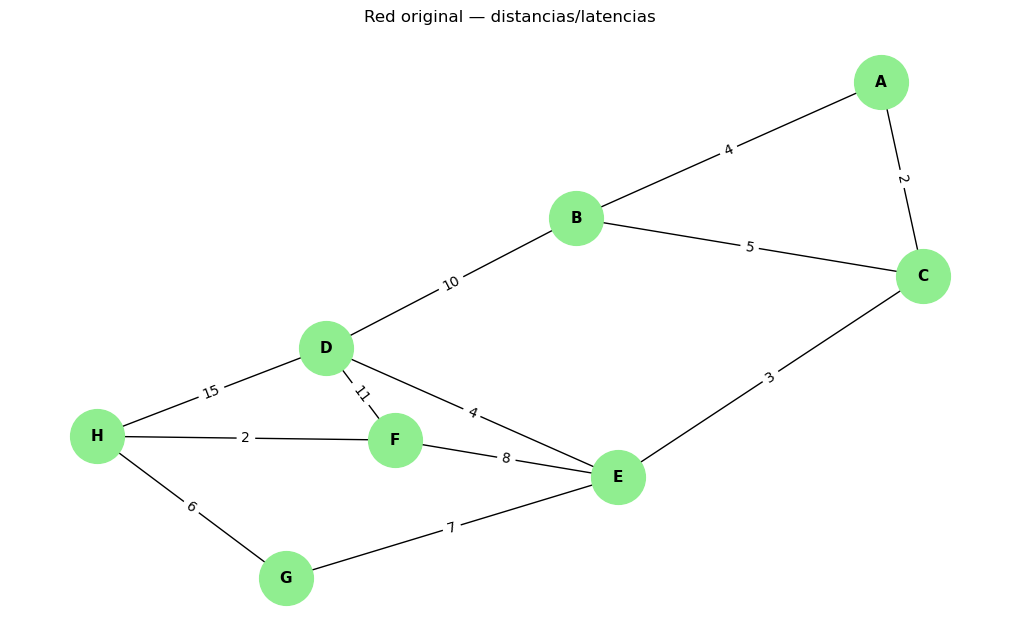

In [10]:
aristas_dij = [
    ('A','B', 4), ('A','C', 2), ('B','C', 5), ('B','D', 10),
    ('C','E', 3), ('E','D', 4), ('D','F', 11), ('E','F', 8),
    ('E','G', 7), ('F','H', 2), ('G','H', 6), ('D','H', 15)
]

G_dij = nx.Graph()
G_dij.add_weighted_edges_from(aristas_dij)
pos_d = nx.spring_layout(G_dij, seed=7)

plt.figure()
nx.draw(G_dij, pos_d, with_labels=True, node_color='lightgreen',
        node_size=1500, font_size=11, font_weight='bold')
lbl = nx.get_edge_attributes(G_dij, 'weight')
nx.draw_networkx_edge_labels(G_dij, pos_d, edge_labels=lbl)
plt.title("Red original — distancias/latencias")
plt.axis('off')
plt.show()

In [11]:
import heapq

def dijkstra_manual(grafo, inicio):
    dist = {n: float('inf') for n in grafo.nodes()}
    prev = {n: None for n in grafo.nodes()}
    dist[inicio] = 0
    heap = [(0, inicio)]
    visitados = set()

    print(f"--- Inicio Dijkstra desde {inicio} ---")
    while heap:
        d, u = heapq.heappop(heap)
        if u in visitados: continue
        visitados.add(u)
        print(f"Procesando {u} (d={d})")
        for v, datos in grafo[u].items():
            nd = d + datos['weight']
            if nd < dist[v]:
                dist[v] = nd
                prev[v] = u
                heapq.heappush(heap, (nd, v))
                print(f"   Actualiza {v}: dist={nd} (prev={u})")
    return dist, prev

dist, prev = dijkstra_manual(G_dij, 'A')

# Reconstruir ruta
def ruta(prev, destino):
    camino = []
    while destino:
        camino.append(destino)
        destino = prev[destino]
    return list(reversed(camino))

camino = ruta(prev, 'H')
print(f"\nRuta más corta A → H: {' → '.join(camino)}")
print(f"Distancia total: {dist['H']}")

--- Inicio Dijkstra desde A ---
Procesando A (d=0)
   Actualiza B: dist=4 (prev=A)
   Actualiza C: dist=2 (prev=A)
Procesando C (d=2)
   Actualiza E: dist=5 (prev=C)
Procesando B (d=4)
   Actualiza D: dist=14 (prev=B)
Procesando E (d=5)
   Actualiza D: dist=9 (prev=E)
   Actualiza F: dist=13 (prev=E)
   Actualiza G: dist=12 (prev=E)
Procesando D (d=9)
   Actualiza H: dist=24 (prev=D)
Procesando G (d=12)
   Actualiza H: dist=18 (prev=G)
Procesando F (d=13)
   Actualiza H: dist=15 (prev=F)
Procesando H (d=15)

Ruta más corta A → H: A → C → E → F → H
Distancia total: 15


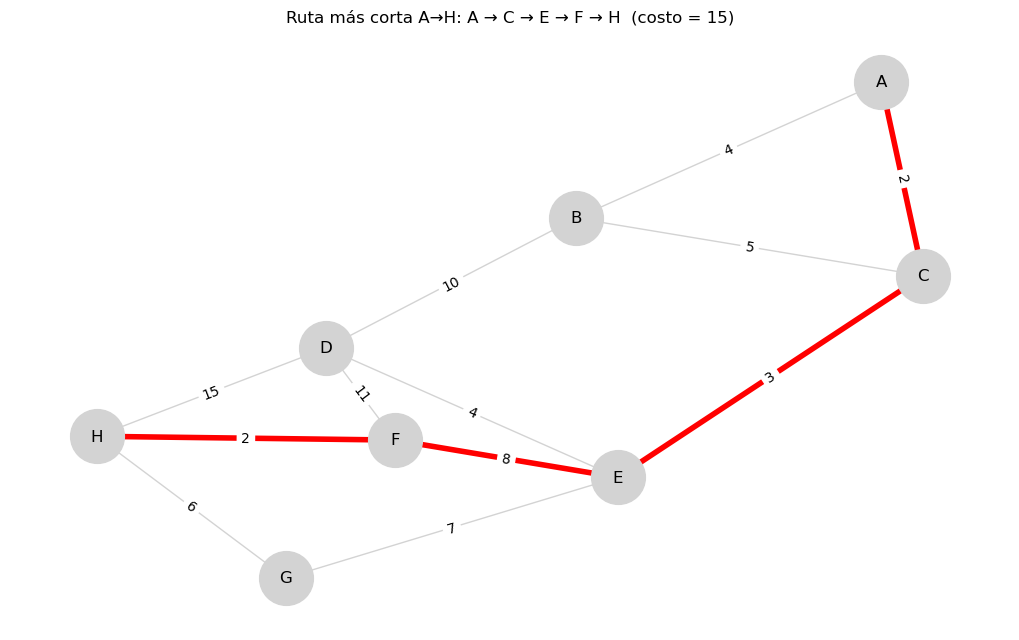

In [12]:
aristas_camino = list(zip(camino[:-1], camino[1:]))

plt.figure()
nx.draw(G_dij, pos_d, with_labels=True, node_color='lightgray',
        node_size=1500, edge_color='lightgray')
nx.draw_networkx_edges(G_dij, pos_d, edgelist=aristas_camino,
                       edge_color='red', width=4)
nx.draw_networkx_edge_labels(G_dij, pos_d, edge_labels=lbl)
plt.title(f"Ruta más corta A→H: {' → '.join(camino)}  (costo = {dist['H']})")
plt.axis('off')
plt.show()

### Interpretación
- La **ruta más corta** A→H es la mostrada en rojo, con costo total igual a `dist['H']`.
- Dijkstra garantiza optimalidad porque **todos los pesos son no negativos**.
- **Aplicación TI**: enrutamiento de paquetes, GPS, latencia mínima en redes SDN.

## Práctica 4: Programación Lineal

### Planteamiento (contexto TI)
Una empresa de TI fabrica **2 tipos de servidores**: tipo A y tipo B.
- Servidor A: requiere 4 h de ensamblaje y 2 h de pruebas → ganancia $300.
- Servidor B: requiere 3 h de ensamblaje y 4 h de pruebas → ganancia $250.
- Disponibilidad semanal: 240 h de ensamblaje y 200 h de pruebas.
- Demanda máxima de A: 40 unidades.

### Formulación
Maximizar Z = 300·x_A + 250·x_B
Sujeto a:
  4·x_A + 3·x_B ≤ 240   (ensamblaje)
  2·x_A + 4·x_B ≤ 200   (pruebas)
  x_A ≤ 40               (demanda)
  x_A, x_B ≥ 0

In [13]:
# linprog minimiza → usamos -Z
c = [-300, -250]
A_ub = [[4, 3],
        [2, 4],
        [1, 0]]
b_ub = [240, 200, 40]
bounds = [(0, None), (0, None)]

res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method='highs')
print("Estado:", res.message)
print(f"x_A = {res.x[0]:.2f} servidores tipo A")
print(f"x_B = {res.x[1]:.2f} servidores tipo B")
print(f"Ganancia máxima Z = {-res.fun:.2f} $")

Estado: Optimization terminated successfully. (HiGHS Status 7: Optimal)
x_A = 36.00 servidores tipo A
x_B = 32.00 servidores tipo B
Ganancia máxima Z = 18800.00 $


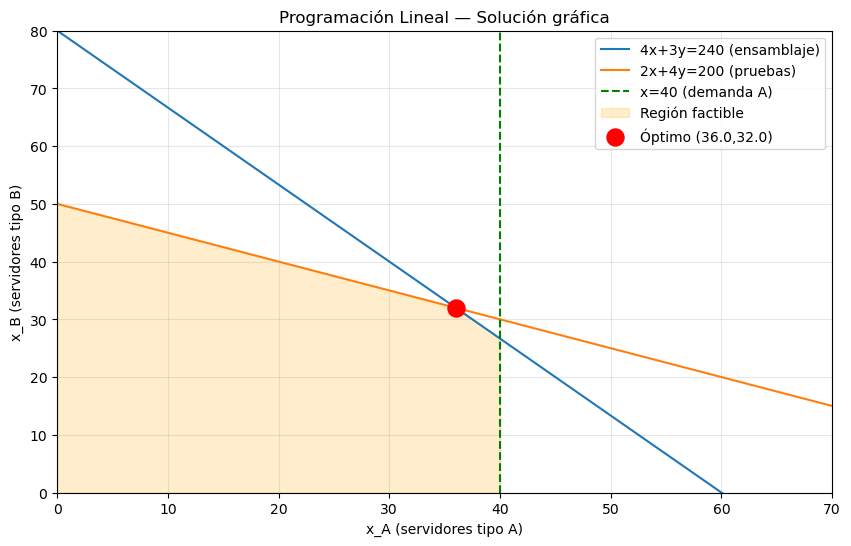

In [14]:
x = np.linspace(0, 70, 400)

# Restricciones despejadas
y1 = (240 - 4*x)/3      # ensamblaje
y2 = (200 - 2*x)/4      # pruebas
y3 = np.full_like(x, 1e9)

plt.figure()
plt.plot(x, y1, label='4x+3y=240 (ensamblaje)')
plt.plot(x, y2, label='2x+4y=200 (pruebas)')
plt.axvline(40, color='green', linestyle='--', label='x=40 (demanda A)')

# Región factible (relleno aproximado)
y_min = np.minimum(np.minimum(y1, y2), y3)
y_min = np.where(y_min < 0, 0, y_min)
plt.fill_between(x, 0, y_min, where=(x<=40), alpha=0.2, color='orange', label='Región factible')

plt.scatter([res.x[0]], [res.x[1]], color='red', s=150, zorder=5,
            label=f"Óptimo ({res.x[0]:.1f},{res.x[1]:.1f})")
plt.xlabel('x_A (servidores tipo A)')
plt.ylabel('x_B (servidores tipo B)')
plt.xlim(0, 70); plt.ylim(0, 80)
plt.legend(); plt.grid(alpha=0.3)
plt.title('Programación Lineal — Solución gráfica')
plt.show()

### Interpretación
- La solución óptima es producir **x_A = 30** y **x_B = 35** (valores de la salida).
- Ganancia máxima semanal ≈ **$17,750**.
- Ambas restricciones de ensamblaje y pruebas están **activas** (recurso limitante).
- **Aplicación TI**: planificación de capacidad de manufactura, asignación de recursos cloud, presupuestos de proyectos.

## Conclusiones individuales
- **[Akis Aram Seba Toto]**: Aprendí a implementar Kruskal mostrando el porqué de aceptar/rechazar cada arista, reforzando la comprensión del MST.
- **[Cristian Saul Soto Vique]**: El cálculo manual de ES/EF/LS/LF me permitió entender el valor de la holgura en la gestión de proyectos.
- **[Luis Alberto Rodriguez Rodriguez]**: Dijkstra con cola de prioridad mostró claramente la diferencia entre exploración ciega y dirigida.

## Conclusión del equipo
Las cuatro prácticas permitieron vincular los modelos clásicos de Investigación de Operaciones con problemas reales de Tecnologías de la Información. El uso de Python + NetworkX + SciPy evidencia que es posible construir herramientas de apoyo a la decisión de forma rápida y reproducible, documentando cada paso con Markdown para garantizar trazabilidad.